# DISCOVERSE：找回的学习策略训练与闭环诊断

旧设备档案中已有500条专家演示、44439帧数据及三种学习策略的训练记录。本篇补齐训练曲线、闭环结果、失败录像与实际原生部署适配器。

ACT［动作分块变换器］训练1000轮，约8小时55分钟，随后未见种子评估0/10；扩散策略训练5000次更新，固定四种子评估0/4；π0.5［视觉语言动作模型］训练专家头500次更新，固定四种子评估0/4。三个结果来自各自的原实验条件，逐项呈现。专家采集成功率另见任务入口。


In [1]:
from pathlib import Path
import json, os, sys
from IPython.display import display, Markdown, Image, HTML
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
E = TOPIC / "notebooks/results/discoverse-history"
def load(name):
    return json.loads((E / name).read_text())
def rows(name):
    out=[]
    for line in (E/name).read_text().splitlines():
        try: out.append(json.loads(line))
        except ValueError: pass
    return out
coverage=load("expert-coverage.json")
print({"专家演示数":coverage["episodes_found"], "完整夹爪阶段":coverage["episodes_with_complete_gripper_phases"], "总帧数":44439})


{'专家演示数': 500, '完整夹爪阶段': 500, '总帧数': 44439}


## 训练和评估分别记录

ACT［动作分块变换器］的1000轮由实际训练日志确认，最终日志保存最佳验证损失及检查点目录；扩散策略指标到第5000次更新；π0.5［视觉语言动作模型］记录已保存检查点、430098464个可训练参数和约11.13 GiB［二进制吉字节］内存峰值。三者都已有闭环评估，不将离线损失当作成功率。


In [2]:
records=[("动作分块策略",load("act-evaluation.json")),("扩散策略",load("diffusion-evaluation.json")),("视觉语言动作策略专家头",load("pi05-evaluation.json"))]
display(Markdown("|策略|训练量|闭环成功|\n|---|---|---|\n"+"\n".join(f"|{label}|{budget}|{d['successes']}/{d['episodes']}|" for (label,d),budget in zip(records,["1000轮","5000次更新","500次更新"]))))
print("动作分块策略：",load("act-epochs.json")["training_finished"])
print("视觉语言动作策略：",{k:load("pi05-training.json")[k] for k in ["checkpoint_saved","steps","dataset_frames","dataset_episodes","trainable_parameters","memory_peak_gib"]})


|策略|训练量|闭环成功|
|---|---|---|
|动作分块策略|1000轮|0/10|
|扩散策略|5000次更新|0/4|
|视觉语言动作策略专家头|500次更新|0/4|

动作分块策略： True
视觉语言动作策略： {'checkpoint_saved': True, 'steps': 500, 'dataset_frames': 44439, 'dataset_episodes': 500, 'trainable_parameters': 430098464, 'memory_peak_gib': 11.130908966064453}


## 保存的完整训练曲线

/home/aup/envs/robocasa365-rocm-py312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


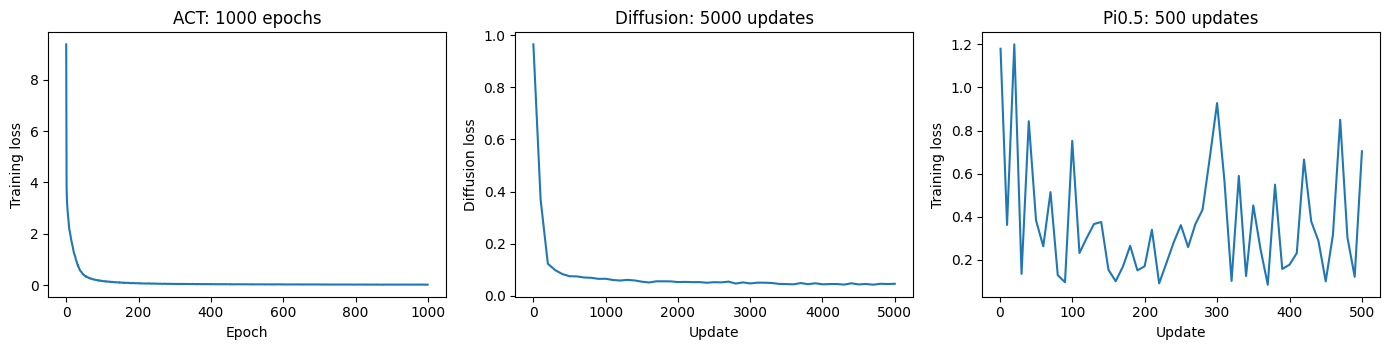

In [3]:
import matplotlib.pyplot as plt
act=load("act-epochs.json")
dp=rows("diffusion-metrics.jsonl")
pi=[r for r in rows("pi05-metrics.jsonl") if r.get("event")=="train"]
assert len(act["train_loss"])==1000 and dp[-1]["step"]==5000 and pi[-1]["step"]==500
fig,ax=plt.subplots(1,3,figsize=(14,3.6))
ax[0].plot(range(1000),act["train_loss"]);ax[0].set(title="ACT: 1000 epochs",xlabel="Epoch",ylabel="Training loss")
ax[1].plot([r["step"] for r in dp],[r["avg_diffusion_loss"] for r in dp]);ax[1].set(title="Diffusion: 5000 updates",xlabel="Update",ylabel="Diffusion loss")
ax[2].plot([r["step"] for r in pi],[r["loss"] for r in pi]);ax[2].set(title="Pi0.5: 500 updates",xlabel="Update",ylabel="Training loss")
fig.tight_layout();display(fig);plt.close(fig)


## 逐回合结果与失败视频

下方录像从原始评估目录复制，完整解码通过。每个评估的全部随机种子、步数和原始双视角路径保存在对应结果文件；相同种子在不同模型实验中的动作调度和接口条件仍以原始记录为准。


### 动作分块策略

|种子|成功|步数|
|---|---|---|
|1000|False|300|
|1001|False|300|
|1002|False|300|
|1003|False|300|
|1004|False|300|
|1005|False|300|
|1006|False|300|
|1007|False|300|
|1008|False|300|
|1009|False|300|

### 扩散策略

|种子|成功|步数|
|---|---|---|
|0|False|304|
|1|False|304|
|1000|False|304|
|1001|False|304|

### 视觉语言动作策略专家头

|种子|成功|步数|
|---|---|---|
|0|False|300|
|1|False|300|
|1000|False|300|
|1001|False|300|

动作分块策略：未见种子失败

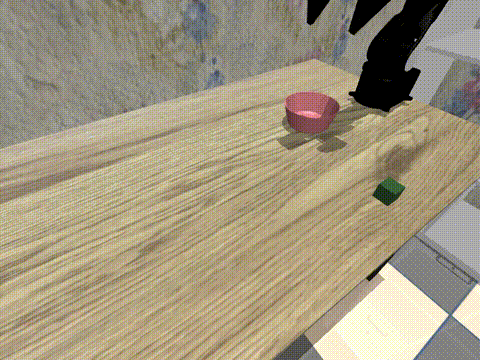

视觉语言动作策略：固定种子失败

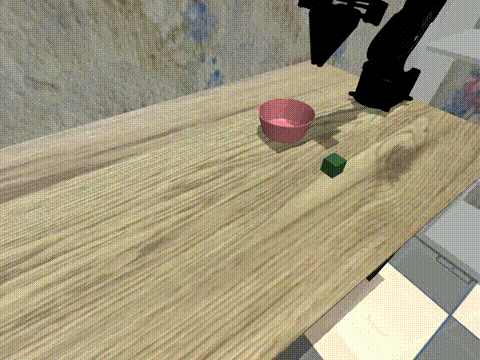

In [4]:
for label,d in records:
    display(Markdown("### "+label))
    display(Markdown("|种子|成功|步数|\n|---|---|---|\n"+"\n".join(f"|{r['seed']}|{r['success']}|{r['steps']}|" for r in d["results"])))
for label,tag in [("动作分块策略：未见种子失败","act"),("视觉语言动作策略：固定种子失败","pi05")]:
    display(Markdown(label));display(Image(filename=str(E/(tag+"-heldout-failure.gif"))))
    relative=os.path.relpath(E/(tag+"-heldout-failure.mp4"),Path.cwd())
    display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))


## 使用真实原生适配器复查

课程现附原生动作分块策略部署脚本 `code/discoverse_pipeline/eval_act_place_block.py`，提供相机颜色顺序、归一化统计、动作拼接、物理步数和逐回合录像接口。它读取原生策略检查点，不能直接读取另一篇 LeRobot 训练命令生成的权重。

若要复查此旧实验，设置 `AMD_REPRO_STAGE=discoverse-native-evaluate`，并设置 `EXPERIMENT_PYTHON`、`DISCOVERSE_NATIVE_ROOT`、`DISCOVERSE_NATIVE_CHECKPOINT`、`DISCOVERSE_NATIVE_STATS`、`DISCOVERSE_EVAL_ROOT`。将输出指向新的外置实验目录。下方显式参数对应旧实验10个未见种子、20赫兹和每回合300步。


In [5]:
import subprocess
if os.environ.get("AMD_REPRO_STAGE")=="discoverse-native-evaluate":
    required=["EXPERIMENT_PYTHON","DISCOVERSE_NATIVE_ROOT","DISCOVERSE_NATIVE_CHECKPOINT","DISCOVERSE_NATIVE_STATS","DISCOVERSE_EVAL_ROOT"]
    for key in required: assert os.environ.get(key),key
    command=[os.environ["EXPERIMENT_PYTHON"],str(TOPIC/"code/discoverse_pipeline/eval_act_place_block.py"),
             "--repo-root",os.environ["DISCOVERSE_NATIVE_ROOT"],"--checkpoint",os.environ["DISCOVERSE_NATIVE_CHECKPOINT"],
             "--stats",os.environ["DISCOVERSE_NATIVE_STATS"],"--output-dir",os.environ["DISCOVERSE_EVAL_ROOT"],
             "--max-steps","300","--control-fps","20","--image-color-order","bgr","--temporal-agg", "--seeds",*[str(s) for s in range(1000,1010)]]
    subprocess.run(command,check=True)
else:
    print("本篇显示已执行的历史训练和闭环结果；未启动新的重复评估。")


本篇显示已执行的历史训练和闭环结果；未启动新的重复评估。


## 还需要补齐什么

1. 另一篇通用 LeRobot 数据转换与训练路线尚缺与该权重格式匹配的完整部署适配器；其原伪代码已明确标为接口说明。
2. 这三种旧学习策略尚未获得该任务的闭环成功，后续要围绕相机颜色、动作／观测对齐、动作连续性及抓放阶段实际排查，并用同种子完整复评记录修复效果。
3. 原生与通用训练路线需要分别固定依赖、数据与归一化统计，避免跨格式加载。原始来源和文件内容指纹见 `notebooks/results/discoverse-history/sources.json`。
